# Mathematical Derivations: Optimal Stopping, NHPP Arrivals & Bellman Recursion

This notebook provides the formal mathematical proofs, stochastic derivations, and phase-space visualizations powering the `optimal-stopping-loml` engine.

---

## 1. Classical Ordinal Stopping & Asymptotic $1/e$ Convergence

Let $N$ candidates arrive in uniformly random rank order, meaning all $N!$ permutations of ranks $(1, 2, \dots, N)$ are equally likely with probability $1/N!$. Suppose we follow a threshold policy with cutoff $r \in \{1, \dots, N-1\}$:
1. Reject the first $r$ candidates automatically and record the benchmark $M_r = \min_{1 \le i \le r} \text{rank}(C_i)$.
2. For candidate $j \in \{r+1, \dots, N\}$, accept the first candidate whose score beats $M_r$.

### Theorem 1.1 (Exact Finite-Sample Win Probability)
The probability $\Phi(r, N)$ of selecting the global rank-1 candidate under cutoff $r$ is:

$$\Phi(r, N) = \frac{r}{N} \sum_{j=r+1}^{N} \frac{1}{j-1}$$

#### Proof
By the law of total probability, decompose the success event over the index $j$ where the global best candidate appears:

$$\Phi(r, N) = \sum_{j=1}^{N} \mathbb{P}(\text{Candidate } j \text{ is chosen} \mid C_j \text{ is Rank 1}) \cdot \mathbb{P}(C_j \text{ is Rank 1})$$

- For $j \le r$, candidate $j$ is unconditionally rejected during the calibration phase, so the conditional probability is $0$.
- For $j > r$, $\mathbb{P}(C_j \text{ is Rank 1}) = \frac{1}{N}$. Given $C_j$ is Rank 1, $C_j$ is chosen if and only if no candidate in $\{r+1, \dots, j-1\}$ beat the benchmark $M_r$. This occurs if and only if the best candidate among the first $j-1$ arrivals appeared within the initial sample $\{1, \dots, r\}$.
- Since arrival positions among the first $j-1$ candidates are uniformly distributed, the probability that the best of the first $j-1$ lies in the first $r$ positions is $\frac{r}{j-1}$.

Summing over $j = r+1, \dots, N$ yields:

$$\Phi(r, N) = \sum_{j=r+1}^{N} \frac{r}{j-1} \cdot \frac{1}{N} = \frac{r}{N} \sum_{j=r+1}^{N} \frac{1}{j-1} \quad \blacksquare$$

### Corollary 1.2 (Continuous Riemann Limit)
Let $x = r/N \in (0, 1)$. As $N \to \infty$, the harmonic sum converges to the definite integral:

$$\lim_{N \to \infty} \Phi(r, N) = x \int_{x}^{1} \frac{1}{t}\,dt = -x \ln x$$

Differentiating with respect to $x$: $\frac{d}{dx}(-x \ln x) = -\ln x - 1 = 0 \implies x^* = e^{-1} \approx 0.36788$, with maximal success probability $\Phi(x^*) = e^{-1}$.

Matplotlib is building the font cache; this may take a moment.


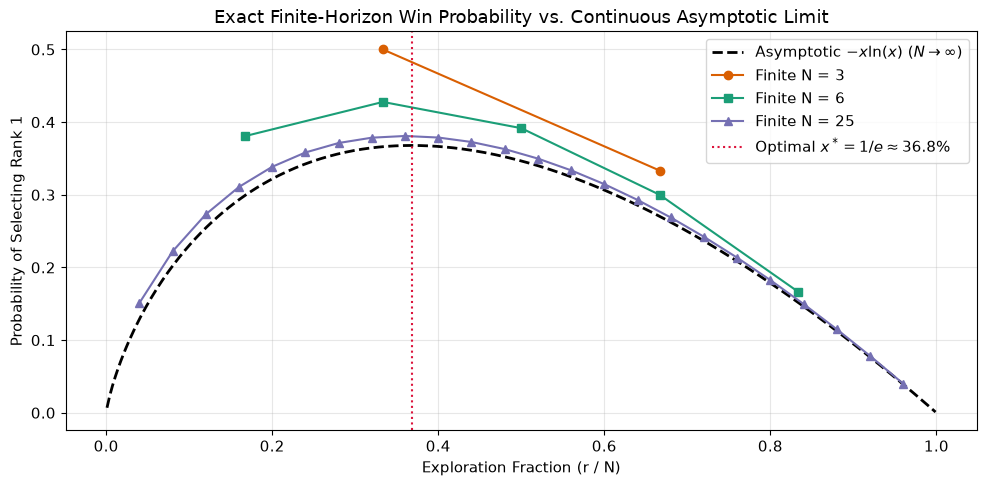

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

plt.rcParams.update({
    'figure.figsize': (10, 5),
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 11
})

def exact_secretary_prob(r: int, N: int) -> float:
    if r <= 0 or r >= N:
        return 1.0 / N if r == 0 else 0.0
    return (r / N) * sum(1.0 / (j - 1) for j in range(r + 1, N + 1))

# Compare finite N=3, N=6, N=20 against asymptotic -x ln(x)
x_cont = np.linspace(0.001, 0.999, 300)
y_asymp = -x_cont * np.log(x_cont)

fig, ax = plt.subplots()
ax.plot(x_cont, y_asymp, 'k--', lw=2, label=r'Asymptotic $-x \ln(x)$ ($N \to \infty$)')

for N, marker, color in [(3, 'o', '#d95f02'), (6, 's', '#1b9e77'), (25, '^', '#7570b3')]:
    r_vals = np.arange(1, N)
    probs = [exact_secretary_prob(int(r), N) for r in r_vals]
    ax.plot(r_vals / N, probs, marker=marker, color=color, lw=1.5, label=f'Finite N = {N}')

ax.axvline(1 / np.e, color='crimson', linestyle=':', label=r'Optimal $x^* = 1/e \approx 36.8\%$')
ax.set_title('Exact Finite-Horizon Win Probability vs. Continuous Asymptotic Limit')
ax.set_xlabel('Exploration Fraction (r / N)')
ax.set_ylabel('Probability of Selecting Rank 1')
ax.legend()
plt.tight_layout()
plt.show()

---

## 2. Non-Homogeneous Poisson Arrival Process & Time-Scale Transformation

In real demographic timelines, candidates do not arrive at a constant Poisson rate $\lambda_0$. Instead, candidate encounters follow a **Non-Homogeneous Poisson Process (NHPP)** over age $t \in [A_{\min}, A_{\max}]$ with intensity $\lambda(t)$:

$$\lambda(t) = \frac{N_{\text{total}}}{A_{\max} - A_{\min}} f_{\text{Beta}}\left(\frac{t - A_{\min}}{A_{\max} - A_{\min}}; \alpha, \beta\right)$$

### Proposition 2.1 (Operational Time-Scale Invariance)
Let $\Lambda(t) = \int_{A_{\min}}^{t} \lambda(u)\,du$ denote the cumulative mean measure. By the time-change theorem for Poisson processes, transforming chronological age $t$ into normalized operational time:

$$\tau(t) = \frac{\Lambda(t)}{\Lambda(A_{\max})} = F_{\text{Beta}}\left(\frac{t - A_{\min}}{A_{\max} - A_{\min}}; \alpha, \beta\right) \in [0, 1]$$

reduces the non-homogeneous stopping problem on $[A_{\min}, A_{\max}]$ to a homogeneous stopping problem on $\tau \in [0, 1]$. Consequently, the chronological optimal exploration age $t^*$ satisfies:

$$F_{\text{Beta}}\left(\frac{t^* - A_{\min}}{A_{\max} - A_{\min}}; \alpha, \beta\right) = \frac{1}{e} \implies t^* = A_{\min} + (A_{\max} - A_{\min}) F_{\text{Beta}}^{-1}\left(\frac{1}{e}; \alpha, \beta\right)$$

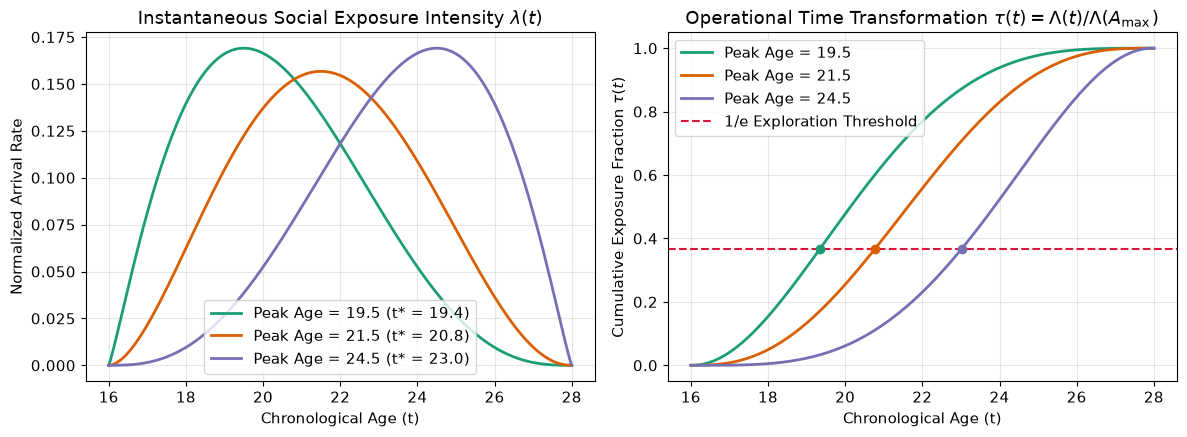

In [2]:
a_min, a_max = 16.0, 28.0
ages = np.linspace(a_min, a_max, 300)
u = (ages - a_min) / (a_max - a_min)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for a_peak, color in [(19.5, '#1b9e77'), (21.5, '#d95f02'), (24.5, '#7570b3')]:
    mode = (a_peak - a_min) / (a_max - a_min)
    conc = 4.0
    a_p = 1.0 + mode * conc
    b_p = 1.0 + (1.0 - mode) * conc
    
    density = beta.pdf(u, a_p, b_p) / (a_max - a_min)
    cum_tau = beta.cdf(u, a_p, b_p)
    t_star = a_min + (a_max - a_min) * beta.ppf(1.0 / np.e, a_p, b_p)
    
    ax1.plot(ages, density, color=color, lw=2, label=f'Peak Age = {a_peak} (t* = {t_star:.1f})')
    ax2.plot(ages, cum_tau, color=color, lw=2, label=f'Peak Age = {a_peak}')
    ax2.scatter([t_star], [1.0 / np.e], color=color, zorder=5)

ax2.axhline(1.0 / np.e, color='crimson', ls='--', label='1/e Exploration Threshold')
ax1.set_title('Instantaneous Social Exposure Intensity $\\lambda(t)$')
ax1.set_xlabel('Chronological Age (t)')
ax1.set_ylabel('Normalized Arrival Rate')
ax1.legend()

ax2.set_title('Operational Time Transformation $\\tau(t) = \\Lambda(t)/\\Lambda(A_{\\max})$')
ax2.set_xlabel('Chronological Age (t)')
ax2.set_ylabel('Cumulative Exposure Fraction $\\tau(t)$')
ax2.legend()
plt.tight_layout()
plt.show()

---

## 3. Full-Information Bellman Optimality & Moser-Cayley Recursion

When candidate utility scores $X_i \overset{\text{i.i.d.}}{\sim} \text{Uniform}(0, 1)$ are observable (calibrated against a population prior), the decision problem transitions from the ordinal Secretary Problem to the **Full-Information Optimal Stopping Problem** with terminal recall fallback.

### Theorem 3.1 (Bellman Backward Recursion with Partial Recall)
Suppose $k$ future candidates remain to be evaluated, and the agent holds a recall option on a past benchmark of percentile $\theta \in (0, 1)$ with effective reconnection probability $p(\Delta t) = p_0 e^{-\gamma \Delta t}$. Let $V_k$ denote the maximal expected percentile score achievable with $k$ draws remaining.

Then the sequence $\{V_k\}_{k=0}^{n_{\text{future}}}$ satisfies the nonlinear difference equation:

$$V_0 = p(\Delta t) \cdot \theta$$

$$V_k = \frac{1 + V_{k-1}^2}{2} \quad \text{for } k \ge 1$$

#### Proof
At step $k$ (with $k$ candidates remaining, including the current candidate $X$), the agent chooses between stopping immediately with payoff $X$ or rejecting $X$ and receiving continuation value $V_{k-1}$. By Bellman's Principle of Optimality:

$$V_k = \mathbb{E}\big[\max(X, V_{k-1})\big]$$

Since $X \sim \text{Uniform}(0, 1)$ and $V_{k-1} \in [0, 1]$, we split the expectation at the reservation threshold $V_{k-1}$:

$$V_k = \int_{0}^{V_{k-1}} V_{k-1}\,dx + \int_{V_{k-1}}^{1} x\,dx = V_{k-1}^2 + \left[\frac{x^2}{2}\right]_{V_{k-1}}^{1} = V_{k-1}^2 + \frac{1 - V_{k-1}^2}{2} = \frac{1 + V_{k-1}^2}{2} \quad \blacksquare$$

The optimal policy at remaining horizon $k$ is therefore to commit if and only if $X \ge V_{k-1}$.

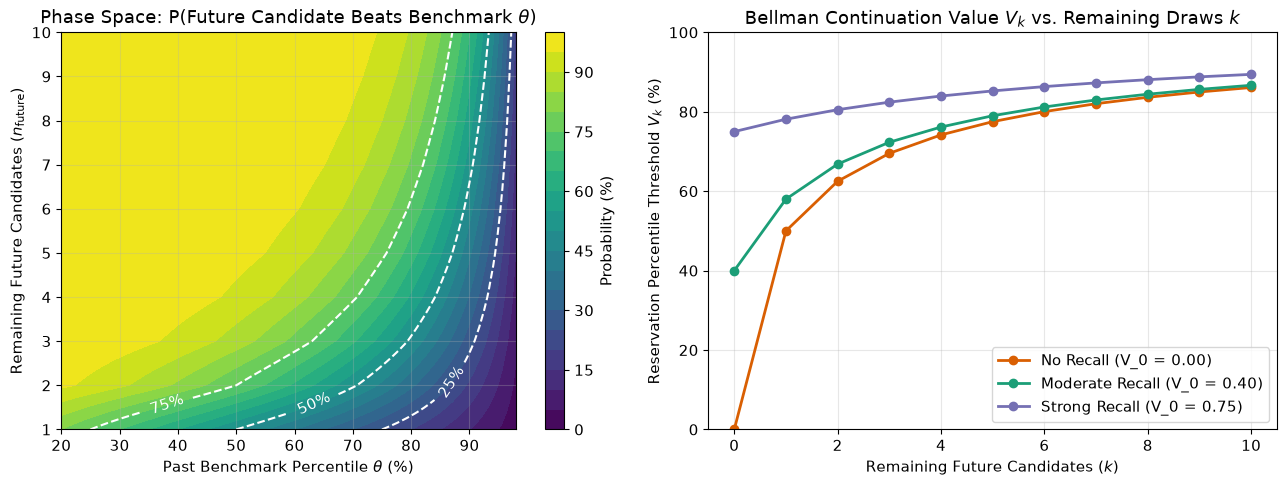

In [3]:
# Phase-Space Visualization: 2D Heatmap of P(LOML in Future | theta, n_future)
# and Bellman Reservation Trajectories across Recall Probabilities

theta_grid = np.linspace(0.20, 0.98, 100)
n_fut_grid = np.arange(1, 11)
THETA, NFUT = np.meshgrid(theta_grid, n_fut_grid)

# Probability that at least one future candidate beats the benchmark theta
PROB_FUTURE_BEATS = (1.0 - THETA ** NFUT) * 100.0

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cp = ax1.contourf(THETA * 100, NFUT, PROB_FUTURE_BEATS, levels=20, cmap='viridis')
cbar = fig.colorbar(cp, ax=ax1)
cbar.set_label('Probability (%)')
cs = ax1.contour(THETA * 100, NFUT, PROB_FUTURE_BEATS, levels=[25, 50, 75], colors='white', linestyles='--')
ax1.clabel(cs, inline=True, fmt='%1.0f%%')
ax1.set_title('Phase Space: P(Future Candidate Beats Benchmark $\\theta$)')
ax1.set_xlabel('Past Benchmark Percentile $\\theta$ (%)')
ax1.set_ylabel('Remaining Future Candidates ($n_{\\mathrm{future}}$)')

# Plot Bellman sequence V_k for different terminal recall values V_0 = p * theta
k_steps = np.arange(0, 11)
for v0, label, col in [(0.0, 'No Recall (V_0 = 0.00)', '#d95f02'),
                       (0.40, 'Moderate Recall (V_0 = 0.40)', '#1b9e77'),
                       (0.75, 'Strong Recall (V_0 = 0.75)', '#7570b3')]:
    v_seq = np.zeros(len(k_steps))
    v_seq[0] = v0
    for k in range(1, len(k_steps)):
        v_seq[k] = 0.5 * (1.0 + v_seq[k - 1] ** 2)
    ax2.plot(k_steps, v_seq * 100, marker='o', lw=2, color=col, label=label)

ax2.set_title('Bellman Continuation Value $V_k$ vs. Remaining Draws $k$')
ax2.set_xlabel('Remaining Future Candidates ($k$)')
ax2.set_ylabel('Reservation Percentile Threshold $V_k$ (%)')
ax2.set_ylim(0, 100)
ax2.legend()
plt.tight_layout()
plt.show()

---

## 4. Cobb-Douglas Multi-Attribute Utility vs. Additive Scoring

Why use a multiplicative Cobb-Douglas functional form $U(\mathbf{s}) = \prod_{k=1}^{K} s_k^{w_k}$ instead of a linear additive sum $U_{\text{lin}}(\mathbf{s}) = \sum_{k=1}^{K} w_k s_k$?

### Proposition 4.1 (Elasticity of Substitution & Structural Collapse)
In a linear utility model, the elasticity of substitution between *Devotion* ($S$) and *Structural Durability* ($D$) is infinite ($\sigma = \infty$), meaning a partner with $D \to 0$ (complete relationship breakdown) can still achieve a high benchmark score if $S = 10$.

Under the Cobb-Douglas specification with normalized weights $\sum w_k = 1$:
1. **Boundary Annihilation:** $\lim_{s_k \to 0^+} \prod_{j=1}^{K} s_j^{w_j} = 0$. Any fatal flaw in durability or reciprocity drives total utility toward zero.
2. **Convex Indifference Curves:** Diminishing marginal rates of substitution prevent single-variable idealization ("the peak trap") from inflating the reservation threshold $\theta$.

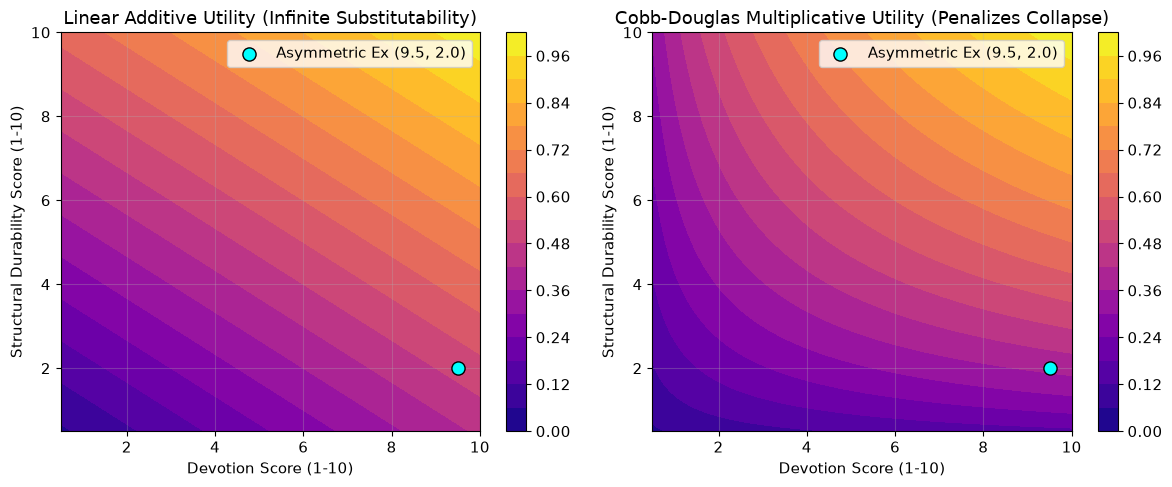

In [4]:
# Indifference Curves & Utility Surface Comparison: Additive vs. Cobb-Douglas
s_devotion = np.linspace(0.5, 10.0, 150) / 10.0
s_durability = np.linspace(0.5, 10.0, 150) / 10.0
S_DEV, S_DUR = np.meshgrid(s_devotion, s_durability)

w_dev, w_dur = 0.4, 0.6
U_additive = w_dev * S_DEV + w_dur * S_DUR
U_cobb_douglas = (S_DEV ** w_dev) * (S_DUR ** w_dur)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

c1 = ax1.contourf(S_DEV * 10, S_DUR * 10, U_additive, levels=15, cmap='plasma')
fig.colorbar(c1, ax=ax1)
ax1.scatter([9.5], [2.0], color='cyan', s=90, edgecolors='black', zorder=5, label='Asymmetric Ex (9.5, 2.0)')
ax1.set_title('Linear Additive Utility (Infinite Substitutability)')
ax1.set_xlabel('Devotion Score (1-10)')
ax1.set_ylabel('Structural Durability Score (1-10)')
ax1.legend()

c2 = ax2.contourf(S_DEV * 10, S_DUR * 10, U_cobb_douglas, levels=15, cmap='plasma')
fig.colorbar(c2, ax=ax2)
ax2.scatter([9.5], [2.0], color='cyan', s=90, edgecolors='black', zorder=5, label='Asymmetric Ex (9.5, 2.0)')
ax2.set_title('Cobb-Douglas Multiplicative Utility (Penalizes Collapse)')
ax2.set_xlabel('Devotion Score (1-10)')
ax2.set_ylabel('Structural Durability Score (1-10)')
ax2.legend()

plt.tight_layout()
plt.show()